# Monte Carlo Simulation of the Binomial Distribution

This simulation demonstrates the Binomial Distribution by running 100,000 experiments. 
Each experiment consists of 50 trials (reviews) with a 95% success rate ($p=0.95$).

In [6]:
import numpy as np
import sympy as sp 
import matplotlib.pyplot as plt

t=sp.symbols('t')
def f(t):
    return (-5*t+2)*(1/t-2/t**2 -15/t**3)
f_prime=sp.diff(f(t),t)
print("f'(t)=",f_prime)

f'(t)= (2 - 5*t)*(-1/t**2 + 4/t**3 + 45/t**4) - 5/t + 10/t**2 + 75/t**3


In [7]:
import sympy as sp 
import numpy as np 

#Do integration  of e^(-y^2) from   negative infinity to positive infinity
y=sp.symbols('y')
integral=sp.integrate(sp.exp(-y**2),(y,-sp.oo,sp.oo))
sp.pprint(integral)

√π


Running 100,000 simulations...


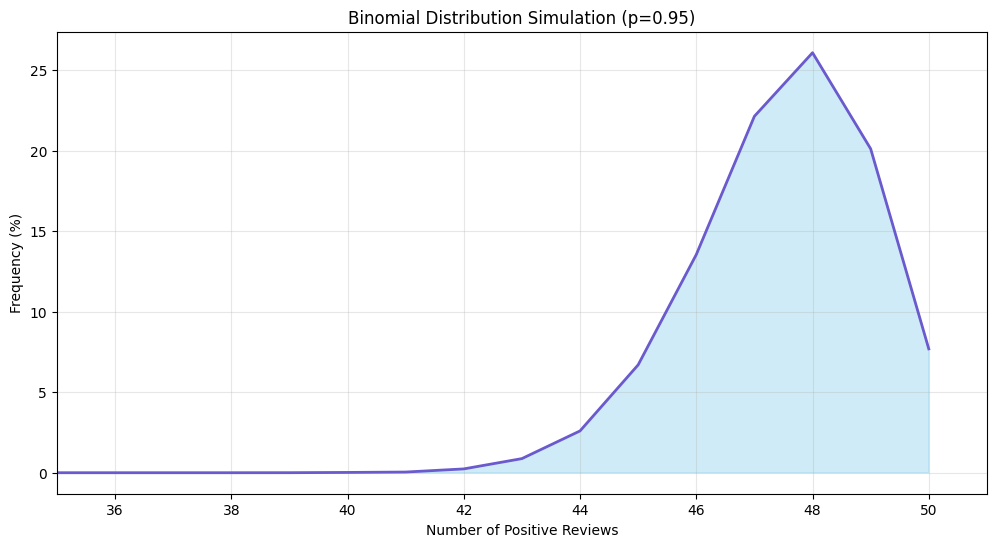

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parameters
n_trials = 50          # Number of reviews in one batch
p_success = 0.95       # Probability of a positive review
n_simulations = 100000 # Number of simulations

print(f"Running {n_simulations:,} simulations...")

# 2. Perform Simulation using NumPy for speed
results = np.random.binomial(n_trials, p_success, n_simulations)

# 3. Calculate Frequencies (Percentages)
counts = np.bincount(results, minlength=n_trials + 1)
percentages = (counts / n_simulations) * 100

# 4. Visualization - Area Chart
plt.figure(figsize=(12, 6))
x_axis = np.arange(0, n_trials + 1)
plt.fill_between(x_axis, percentages, color="skyblue", alpha=0.4, label="Simulation Probability")
plt.plot(x_axis, percentages, color="Slateblue", linewidth=2)
plt.title(f"Binomial Distribution Simulation (p={p_success})")
plt.xlabel("Number of Positive Reviews")
plt.ylabel("Frequency (%)")
plt.xlim(35, 51)
plt.grid(True, alpha=0.3)
plt.show()

# Central Limit Theorem (CLT) Illustration

This simulation shows how the average of many biased events (like rolling a heavy die) always results in a **Gaussian Bell Curve**.

Simulating 1,000,000 sets of 500 biased rolls...


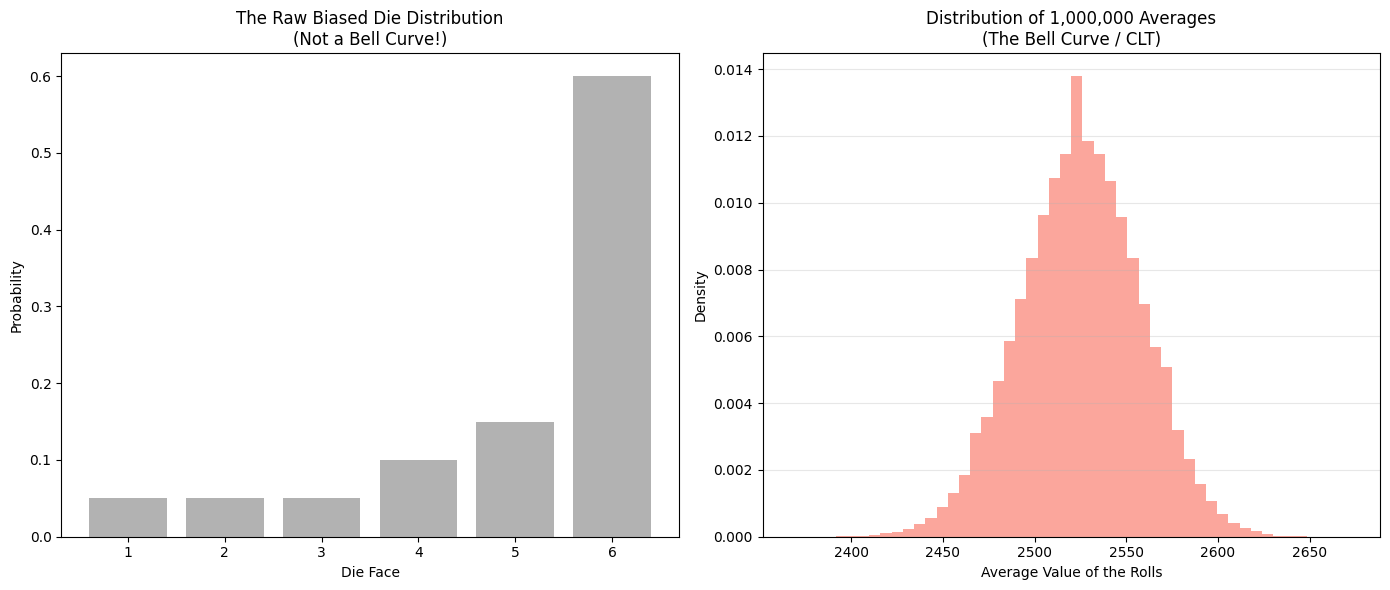

Notice how the chaotic, biased die becomes a smooth, symmetric Bell Curve when we take the averages.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a Heavily Biased Die
# Faces: [1, 2, 3, 4, 5, 6]
# Probabilities: Highly likely to roll a 6, very unlikely to roll a 1
faces = np.array([1, 2, 3, 4, 5, 6])
probs = np.array([0.05, 0.05, 0.05, 0.1, 0.15, 0.6]) # Sum = 1.0

# 2. Simulation Parameters
n_rolls_per_sample = 500 # How many times we roll the die before taking the average
n_samples = 1_000_000      # How many averages we calculate

print(f"Simulating {n_samples:,} sets of {n_rolls_per_sample} biased rolls...")

# 3. The CLT Magic: Take the Mean of the Means
means = []
for _ in range(n_samples):
    # Roll the biased die n times
    sample = np.random.choice(faces, size=n_rolls_per_sample, p=probs)
    # Record the average of this set
    means.append(np.sum(sample))

# 4. Visualization
plt.figure(figsize=(14, 6))

# Subplot 1: The Raw Biased Die (The 'Chaos')
plt.subplot(1, 2, 1)
plt.bar(faces, probs, color='grey', alpha=0.6)
plt.title("The Raw Biased Die Distribution\n(Not a Bell Curve!)")
plt.xlabel("Die Face")
plt.ylabel("Probability")
plt.xticks(faces)

# Subplot 2: The Distribution of Means (The 'Order')
plt.subplot(1, 2, 2)
plt.hist(means, bins=50, color='salmon', alpha=0.7, density=True)
plt.title(f"Distribution of {n_samples:,} Averages\n(The Bell Curve / CLT)")
plt.xlabel("Average Value of the Rolls")
plt.ylabel("Density")
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice how the chaotic, biased die becomes a smooth, symmetric Bell Curve when we take the averages.")

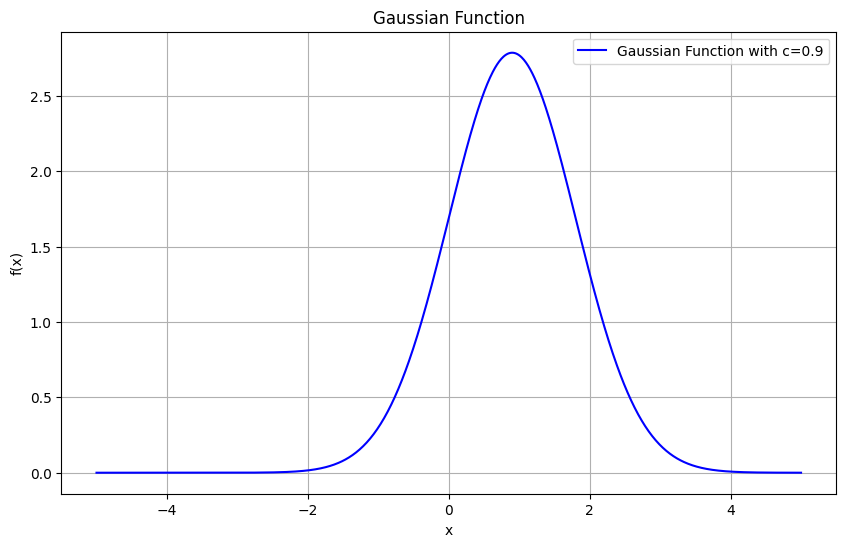

In [10]:
import numpy as np 
import matplotlib.pyplot as plt

def gaussian(x,c,u):
    #k ^(-cx**2)
    return np.exp(-0.5 * ((x-u)/c)**2)/c*np.sqrt(2*np.pi)
#parameters
c=0.9
u=0.9
x=np.linspace(-5,5,1000)
y=gaussian(x,c,u)
#plotting
plt.figure(figsize=(10,6))
plt.plot(x,y,color='blue',label=f'Gaussian Function with c={c}')
plt.title('Gaussian Function')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.legend()
plt.show()


In [11]:
#log to base 8 3 is equal to p
#log to base 4 3 is equal to q
#what is value of p and q
import math
#math.log(x,base) gives logarithm of x to the specified base
p=math.log(3,8)
q=math.log(3,4)
print(f"p(log base 8 of 3)= {p}")
print(f"q(log base 4 of 3)= {q}")

p(log base 8 of 3)= 0.5283208335737188
q(log base 4 of 3)= 0.7924812503605781


Herschel-Maxwell Derivation

C:\Users\del\AppData\Local\Temp\ipykernel_6600\3938867697.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


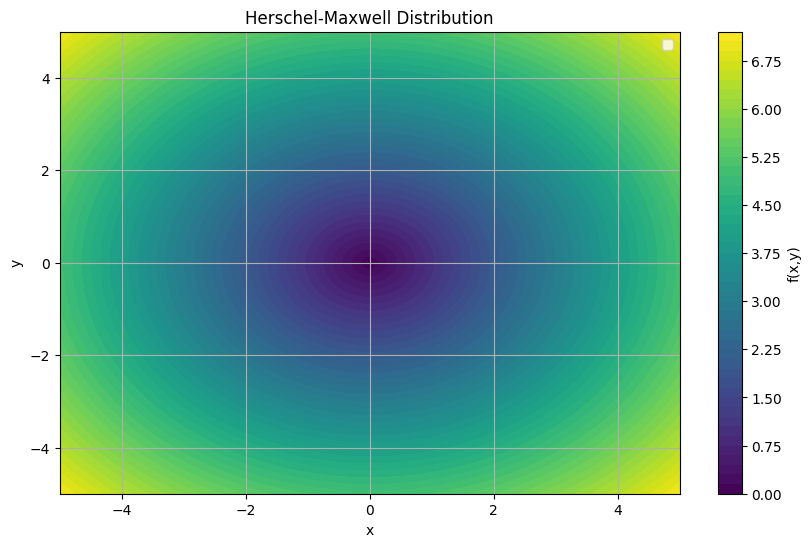

In [12]:
import numpy as np 
import matplotlib.pyplot as plt

def herschel_maxwell(x,y):
    return (np.sqrt(x**2+y**2))
x=np.linspace(-5,5,100)
y=np.linspace(-5,5,100)
X,Y=np.meshgrid(x,y)
Z=herschel_maxwell(X,Y)
plt.figure(figsize=(10,6))
plt.contourf(X,Y,Z, levels=50, cmap='viridis')
plt.colorbar(label='f(x,y)')
plt.title('Herschel-Maxwell Distribution')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()
plt.show()


CONVOLUTION

In [14]:
import numpy as np
import scipy.signal as signal 
import random 

arr1=np.random.rand(100_000)
arr2=np.random.rand(100_000)

In [15]:

%%timeit
array=np.convolve(arr1,arr2)
print("Convolution Result:", array)



Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
24.4 s ± 2.74 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [17]:
%%timeit
array=signal.fftconvolve(arr1,arr2)
print("FFT Convolution Result:", array)

FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46931192 0.72905712 ... 1.26611688 0.69280122 0.13324333]
FFT Convolution Result: [0.29966591 0.46